Total raw rows loaded: 7386
Usable Labeled Rows for Training/Testing: 7362
Unlabeled Rows (to be predicted later): 24
Model: Risk_Level ~ AVG_NOISE_LVL + Duration_hours
Data Split: 90% Train (6625 rows) | 10% Test (737 rows)
Train R²: 80.15% | Test R²: 79.91% | Test RMSE: 0.3020
Custom Prediction: When (AVG_NOISE_LVL=55, Duration_hours=2)  -->  Predicted Risk_Level = 1.5269
Custom Prediction: When (AVG_NOISE_LVL=85, Duration_hours=8)  -->  Predicted Risk_Level = 4.3820


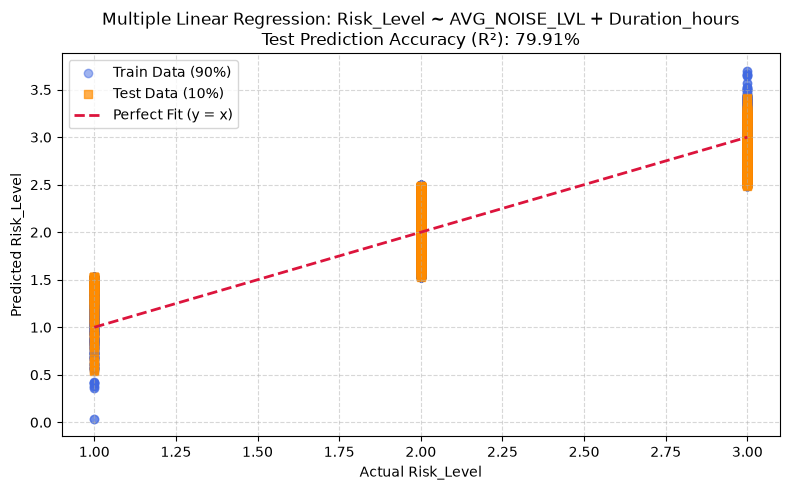

Model: Risk_Level ~ AVG_NOISE_LVL + Duration_hours + LATITUDE
Data Split: 90% Train (6625 rows) | 10% Test (737 rows)
Train R²: 80.16% | Test R²: 79.88% | Test RMSE: 0.3022
Custom Prediction: When (AVG_NOISE_LVL=55.0, Duration_hours=2.0, LATITUDE=12.91)  -->  Predicted Risk_Level = 1.3222
Custom Prediction: When (AVG_NOISE_LVL=85.0, Duration_hours=8.0, LATITUDE=13.05)  -->  Predicted Risk_Level = 4.1836


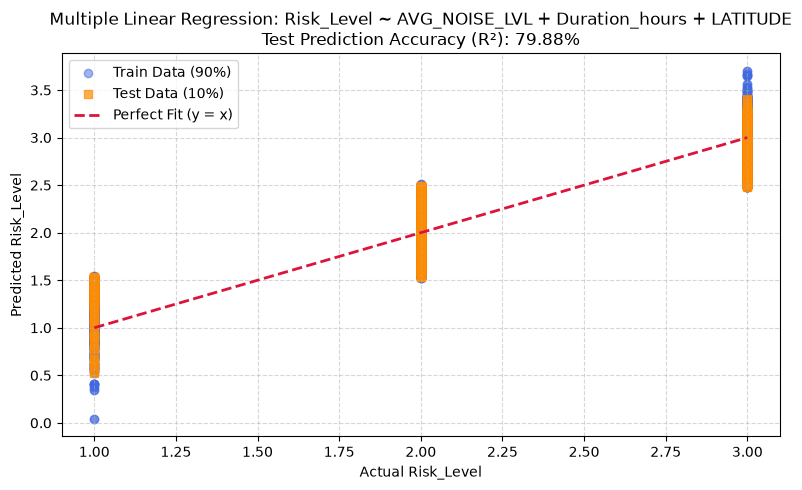

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

print(f"Total raw rows loaded: {len(df)}")

# ==========================================================
# Universal Risk_Level Parser (Handles text, floats & string floats)
# ==========================================================
def parse_risk(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower().replace(".0", "")
    mapping = {
        "1": 1.0, "low": 1.0, "l": 1.0,
        "2": 2.0, "medium": 2.0, "med": 2.0, "moderate": 2.0, "m": 2.0,
        "3": 3.0, "high": 3.0, "h": 3.0, "severe": 3.0
    }
    return mapping.get(s, np.nan)

df["Risk_Level"] = df["Risk_Level"].apply(parse_risk)

# Convert numeric feature columns
feature_cols = ["AVG_NOISE_LVL", "Duration_hours", "LATITUDE", "LONGITUDE"]
for col in feature_cols:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace(r"[^\d.-]", "", regex=True)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Usable Labeled Rows for Training/Testing: {df['Risk_Level'].notna().sum()}")
print(f"Unlabeled Rows (to be predicted later): {df['Risk_Level'].isna().sum()}")

# ==========================================================
# Create TownCode (Latitude -> Longitude)
# ==========================================================
if "TOWN" in df.columns and "LATITUDE" in df.columns and "LONGITUDE" in df.columns:
    town_locations = (
        df.groupby("TOWN")[["LATITUDE", "LONGITUDE"]]
        .first()
        .reset_index()
    )
    town_locations = town_locations.sort_values(
        by=["LATITUDE", "LONGITUDE"], ascending=[True, True]
    ).reset_index(drop=True)
    town_locations["TownCode"] = range(1, len(town_locations) + 1)

    df = df.merge(town_locations[["TOWN", "TownCode"]], on="TOWN", how="left")

# ==========================================================
# 80/20 Train-Test Split & Plot Function for Multiple Regression
# ==========================================================
def train_test_and_plot_multilinear(df, x_cols, y_col, custom_inputs=None, test_size=0.20, random_state=42):
    cols_to_use = x_cols + [y_col]
    data = df[cols_to_use].dropna().copy()

    if len(data) < 5:
        print(f"Not enough valid data points for {y_col} ~ {' + '.join(x_cols)}")
        return

    # Split dataset: 80% Train, 20% Test
    train_data, test_data = train_test_split(
        data, test_size=test_size, random_state=random_state
    )

    # 1. Train Model on 80% Training Data
    X_train = sm.add_constant(train_data[x_cols])
    Y_train = train_data[y_col]
    model = sm.OLS(Y_train, X_train).fit()

    # 2. Predict on 20% Test Data and Training Data
    X_test = sm.add_constant(test_data[x_cols], has_constant="add")
    Y_train_pred = model.predict(X_train)
    Y_test_pred = model.predict(X_test)

    train_r2 = r2_score(Y_train, Y_train_pred) * 100
    test_r2 = r2_score(test_data[y_col], Y_test_pred) * 100
    test_rmse = np.sqrt(mean_squared_error(test_data[y_col], Y_test_pred))

    # 3. Predict for Custom Inputs
    custom_preds = None
    if custom_inputs is not None:
        custom_df = pd.DataFrame(custom_inputs)
        X_custom = sm.add_constant(custom_df, has_constant="add")
        X_custom = X_custom[X_train.columns]
        custom_preds = model.predict(X_custom)

    print("=" * 70)
    print(f"Model: {y_col} ~ {' + '.join(x_cols)}")
    print(f"Data Split: {int((1-test_size)*100)}% Train ({len(train_data)} rows) | {int(test_size*100)}% Test ({len(test_data)} rows)")
    print(f"Train R²: {train_r2:.2f}% | Test R²: {test_r2:.2f}% | Test RMSE: {test_rmse:.4f}")
    
    if custom_inputs is not None and custom_preds is not None:
        for idx, row in custom_df.iterrows():
            inputs_str = ", ".join([f"{col}={row[col]}" for col in x_cols])
            print(f"Custom Prediction: When ({inputs_str})  -->  Predicted {y_col} = {custom_preds.iloc[idx]:.4f}")
    print("=" * 70)

    # Visual Plot: Actual vs Predicted
    plt.figure(figsize=(8, 5))
    plt.scatter(Y_train, Y_train_pred, color="royalblue", alpha=0.5, label=f"Train Data ({int((1-test_size)*100)}%)")
    plt.scatter(test_data[y_col], Y_test_pred, color="darkorange", alpha=0.7, marker="s", label=f"Test Data ({int(test_size*100)}%)")

    min_val, max_val = data[y_col].min(), data[y_col].max()
    plt.plot([min_val, max_val], [min_val, max_val], color="crimson", linestyle="--", linewidth=2, label="Perfect Fit (y = x)")

    plt.xlabel(f"Actual {y_col}")
    plt.ylabel(f"Predicted {y_col}")
    plt.title(f"Multiple Linear Regression: {y_col} ~ {' + '.join(x_cols)}\nTest Prediction Accuracy (R²): {test_r2:.2f}%")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{y_col}_vs_{'_'.join(x_cols)}_multilinear.png", dpi=300)
    plt.show()

    return model

# ==========================================================
# Run Multiple Linear Regression Models
# ==========================================================

# Model 1: Without Latitude
model1 = train_test_and_plot_multilinear(
    df=df,
    x_cols=["AVG_NOISE_LVL", "Duration_hours"],
    y_col="Risk_Level",
    custom_inputs=[
        {"AVG_NOISE_LVL": 55, "Duration_hours": 2},
        {"AVG_NOISE_LVL": 85, "Duration_hours": 8}
    ],
    test_size=0.10
)

# Model 2: With Latitude
model2 = train_test_and_plot_multilinear(
    df=df,
    x_cols=["AVG_NOISE_LVL", "Duration_hours", "LATITUDE"],
    y_col="Risk_Level",
    custom_inputs=[
        {"AVG_NOISE_LVL": 55, "Duration_hours": 2, "LATITUDE": 12.91},
        {"AVG_NOISE_LVL": 85, "Duration_hours": 8, "LATITUDE": 13.05}
    ],
    test_size=0.10
)